<a href="https://colab.research.google.com/github/bhumikaagrawal000/visual-stimulus-analysis/blob/main/Project_1_Visual_Stimulus_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Project 1: Computational Analysis of Visual Stimuli Using Python

In [16]:
a = 10
b = 5

print(a + b)
print(a - b)
print(a * b)
print(a / b)

15
5
50
2.0


STAGE 1 — Basic Image Analysis

In [17]:
import numpy as np

In [18]:
import numpy as np

image = np.array([
    [0, 50, 100],
    [50, 100, 150],
    [100, 150, 200]
])

print(image)

[[  0  50 100]
 [ 50 100 150]
 [100 150 200]]


In [19]:
mean_luminance = np.mean(image)

print(mean_luminance)

100.0


In [20]:
contrast = np.std(image)

print(contrast)

57.735026918962575


In [21]:
import matplotlib.pyplot as plt

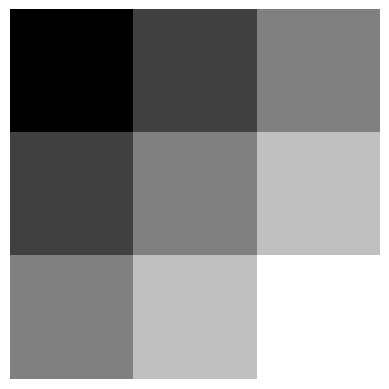

In [22]:
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

Mean luminance: 100.0
Contrast: 57.735026918962575


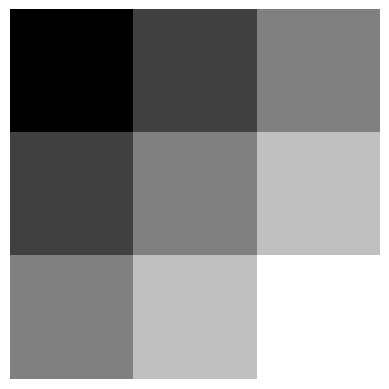

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Create a simple visual stimulus
image = np.array([
    [0, 50, 100],
    [50, 100, 150],
    [100, 150, 200]
])

# Calculate mean luminance
mean_luminance = np.mean(image)

# Calculate contrast
contrast = np.std(image)

# Display the results
print("Mean luminance:", mean_luminance)
print("Contrast:", contrast)

# Display the visual stimulus
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

In [24]:
from PIL import Image

In [25]:
import numpy as np
from PIL import Image

# Automatically generate a dummy stimulus1.png if it does not exist
try:
    image = Image.open("stimulus1.png")
except FileNotFoundError:
    # Create a 256x256 grayscale dummy image and save it
    dummy_data = np.arange(256, dtype=np.uint8).reshape(1, 256).repeat(256, axis=0)
    dummy_image = Image.fromarray(dummy_data, mode="L")
    dummy_image.save("stimulus1.png")
    image = Image.open("stimulus1.png")

print(image)

<PIL.WebPImagePlugin.WebPImageFile image mode=RGB size=800x800 at 0x7A48EC49EC10>


In [51]:
from google.colab import files

# This will prompt you to choose a file from your computer to upload
uploaded = files.upload()

for fn in uploaded.keys():
  print(f'Successfully uploaded file "{fn}" ({len(uploaded[fn])} bytes)')

Saving stimulus1.png to stimulus1 (1).png
Successfully uploaded file "stimulus1 (1).png" (16258 bytes)


In [59]:
import os

# Check if the renamed uploaded file exists
if os.path.exists("stimulus1 (1).png"):
    # Remove the dummy placeholder image
    if os.path.exists("stimulus1.png"):
        os.remove("stimulus1.png")
        print("Removed dummy placeholder 'stimulus1.png'.")

    # Rename your uploaded file to 'stimulus1.png'
    os.rename("stimulus1 (1).png", "stimulus1.png")
    print("Successfully renamed 'stimulus1 (1).png' to 'stimulus1.png'!")

    # Reload the image correctly
    image = Image.open("stimulus1.png")
    print("Your image loaded successfully:", image)
else:
    print("The file 'stimulus1 (1).png' was not found. Please ensure your upload completed successfully.")

The file 'stimulus1 (1).png' was not found. Please ensure your upload completed successfully.


In [60]:
gray_image = image.convert("L")

print(gray_image.mode)

L


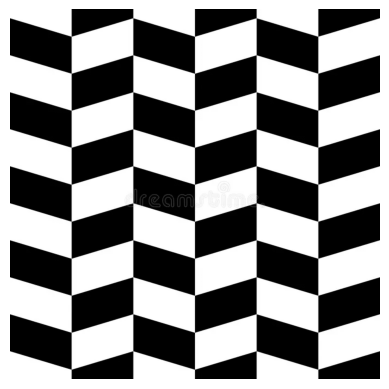

In [61]:
plt.imshow(gray_image, cmap="gray")
plt.axis("off")
plt.show()

In [62]:
image_array = np.array(gray_image)

print(image_array)

[[255 255 255 ...   0   0   0]
 [255 255 255 ...   0   0   0]
 [255 255 255 ...   0   0   0]
 ...
 [255 255 255 ...   0   0   0]
 [255 255 255 ...   0   0   0]
 [255 255 255 ...   0   0   0]]


In [63]:
print(image_array.shape)

(800, 800)


In [64]:
mean_luminance = np.mean(image_array)
contrast = np.std(image_array)

print("Mean luminance:", mean_luminance)
print("Contrast:", contrast)

Mean luminance: 127.743403125
Contrast: 126.28055211480009


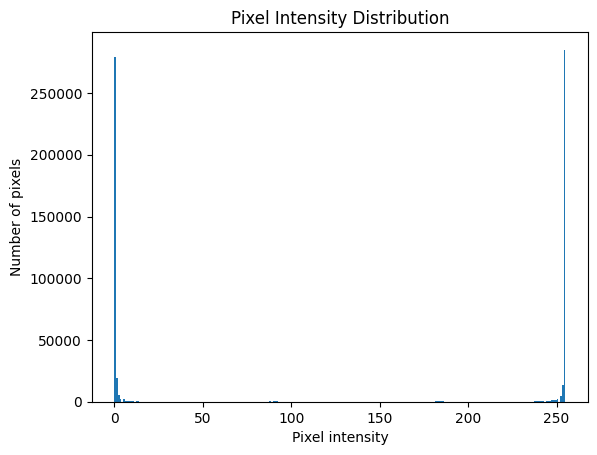

In [65]:
plt.hist(image_array.flatten(), bins=256)

plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.title("Pixel Intensity Distribution")

plt.show()

STAGE 2 — CONTROLLED VISUAL STIMULUS GENERATION

In [66]:
import numpy as np
import matplotlib.pyplot as plt

In [67]:
width = 500
height = 500

In [68]:
cycles = 5

In [69]:
x = np.linspace(0, 2 * np.pi * cycles, width)

In [70]:
wave = np.sin(x)

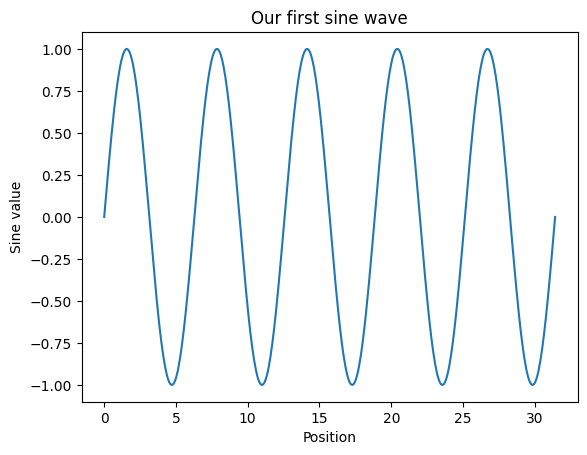

In [71]:
plt.plot(x, wave)
plt.xlabel("Position")
plt.ylabel("Sine value")
plt.title("Our first sine wave")
plt.show()

In [72]:
grating = np.tile(wave, (height, 1))

In [73]:
stimulus = (grating + 1) / 2

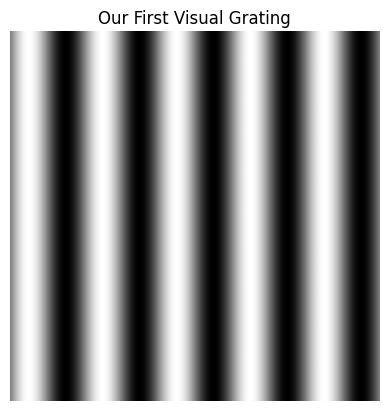

In [74]:
plt.imshow(stimulus, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.title("Our First Visual Grating")
plt.show()

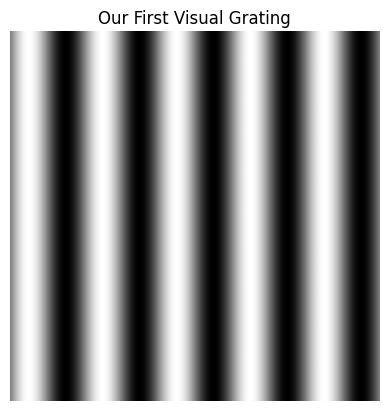

In [75]:
import numpy as np
import matplotlib.pyplot as plt

# Size of the visual stimulus
width = 500
height = 500

# Number of repeating cycles
cycles = 5

# Create evenly spaced positions
x = np.linspace(0, 2 * np.pi * cycles, width)

# Create a sine wave
wave = np.sin(x)

# Repeat the wave vertically to create a 2D image
grating = np.tile(wave, (height, 1))

# Convert values from -1 to +1 into 0 to 1
stimulus = (grating + 1) / 2

# Display the stimulus
plt.imshow(stimulus, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.title("Our First Visual Grating")
plt.show()

In [76]:
minimum = np.min(stimulus)

print("Minimum intensity:", minimum)

Minimum intensity: 2.4772983469589782e-06


In [77]:
maximum = np.max(stimulus)

print("Maximum intensity:", maximum)

Maximum intensity: 0.9999975227016531


In [78]:
mean_luminance = np.mean(stimulus)

print("Mean luminance:", mean_luminance)

Mean luminance: 0.5


In [79]:
contrast_sd = np.std(stimulus)

print("Standard deviation:", contrast_sd)

Standard deviation: 0.3531996602489872


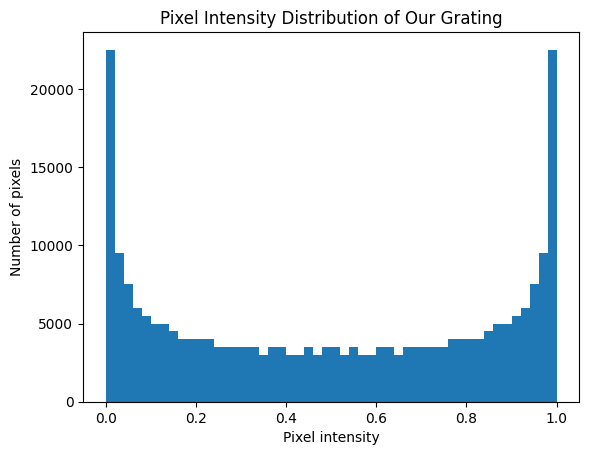

In [80]:
plt.hist(stimulus.flatten(), bins=50)

plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.title("Pixel Intensity Distribution of Our Grating")

plt.show()

In [81]:
L_max = np.max(stimulus)
L_min = np.min(stimulus)

michelson_contrast = (L_max - L_min) / (L_max + L_min)

print("Michelson contrast:", michelson_contrast)

Michelson contrast: 0.9999950454033062


In [83]:
low_contrast = 0.2

low_stimulus = 0.5 + low_contrast * (stimulus - 0.5)

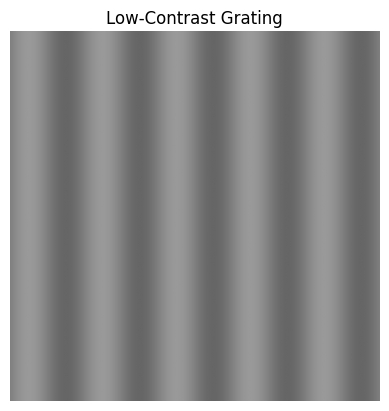

In [84]:
plt.imshow(low_stimulus, cmap="gray", vmin=0, vmax=1)

plt.axis("off")
plt.title("Low-Contrast Grating")

plt.show()

In [85]:
low_min = np.min(low_stimulus)
low_max = np.max(low_stimulus)
low_mean = np.mean(low_stimulus)

low_michelson = (low_max - low_min) / (low_max + low_min)

print("Minimum:", low_min)
print("Maximum:", low_max)
print("Mean luminance:", low_mean)
print("Michelson contrast:", low_michelson)

Minimum: 0.40000049545966937
Maximum: 0.5999995045403306
Mean luminance: 0.5
Michelson contrast: 0.1999990090806612


In [86]:
medium_contrast = 0.5

medium_stimulus = 0.5 + medium_contrast * (stimulus - 0.5)

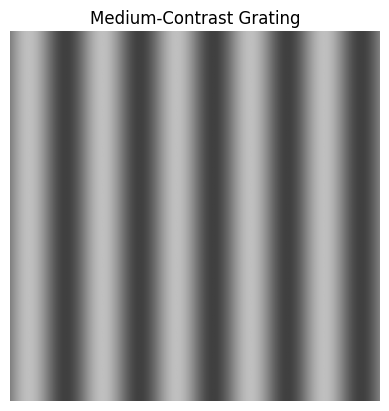

In [87]:
plt.imshow(medium_stimulus, cmap="gray", vmin=0, vmax=1)

plt.axis("off")
plt.title("Medium-Contrast Grating")

plt.show()

In [88]:
medium_min = np.min(medium_stimulus)
medium_max = np.max(medium_stimulus)
medium_mean = np.mean(medium_stimulus)

medium_michelson = (medium_max - medium_min) / (medium_max + medium_min)

print("Minimum:", medium_min)
print("Maximum:", medium_max)
print("Mean luminance:", medium_mean)
print("Michelson contrast:", medium_michelson)

Minimum: 0.25000123864917345
Maximum: 0.7499987613508265
Mean luminance: 0.5
Michelson contrast: 0.4999975227016531


In [89]:
high_contrast = 1.0

high_stimulus = 0.5 + high_contrast * (stimulus - 0.5)

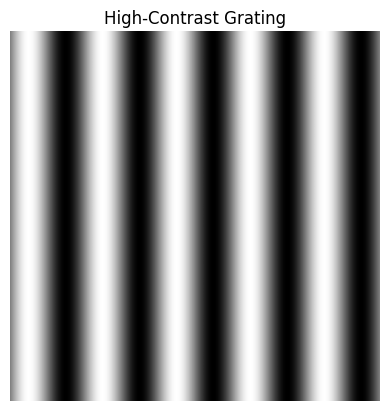

In [90]:
plt.imshow(high_stimulus, cmap="gray", vmin=0, vmax=1)

plt.axis("off")
plt.title("High-Contrast Grating")

plt.show()

In [91]:
high_min = np.min(high_stimulus)
high_max = np.max(high_stimulus)
high_mean = np.mean(high_stimulus)

high_michelson = (high_max - high_min) / (high_max + high_min)

print("Minimum:", high_min)
print("Maximum:", high_max)
print("Mean luminance:", high_mean)
print("Michelson contrast:", high_michelson)

Minimum: 2.4772983469589782e-06
Maximum: 0.9999975227016531
Mean luminance: 0.5
Michelson contrast: 0.9999950454033062


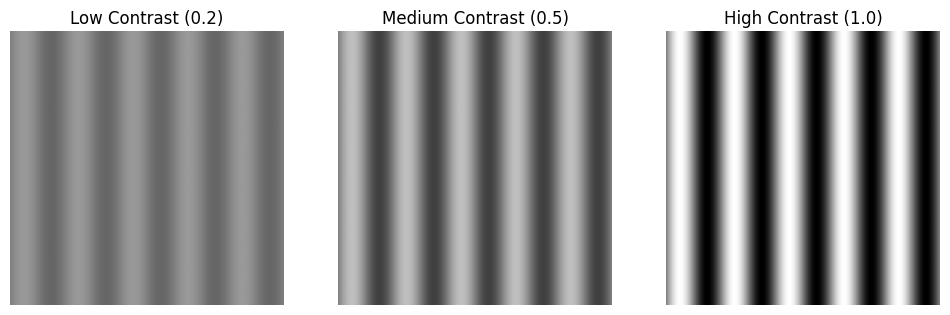

In [92]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(low_stimulus, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.title("Low Contrast (0.2)")

plt.subplot(1, 3, 2)
plt.imshow(medium_stimulus, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.title("Medium Contrast (0.5)")

plt.subplot(1, 3, 3)
plt.imshow(high_stimulus, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.title("High Contrast (1.0)")

plt.show()

In [93]:

import pandas as pd

# Calculate measurements for each stimulus

def measure_stimulus(image):
    minimum = np.min(image)
    maximum = np.max(image)
    mean = np.mean(image)

    contrast = (maximum - minimum) / (maximum + minimum)

    return minimum, maximum, mean, contrast


# Measure all three gratings

low_results = measure_stimulus(low_stimulus)
medium_results = measure_stimulus(medium_stimulus)
high_results = measure_stimulus(high_stimulus)


# Create a results table

results = pd.DataFrame({
    "Stimulus": ["Low", "Medium", "High"],
    "Minimum intensity": [
        low_results[0], medium_results[0], high_results[0]
    ],
    "Maximum intensity": [
        low_results[1], medium_results[1], high_results[1]
    ],
    "Mean luminance": [
        low_results[2], medium_results[2], high_results[2]
    ],
    "Michelson contrast": [
        low_results[3], medium_results[3], high_results[3]
    ]
})

print(results.round(4))


  Stimulus  Minimum intensity  Maximum intensity  Mean luminance  \
0      Low               0.40               0.60             0.5   
1   Medium               0.25               0.75             0.5   
2     High               0.00               1.00             0.5   

   Michelson contrast  
0                 0.2  
1                 0.5  
2                 1.0  


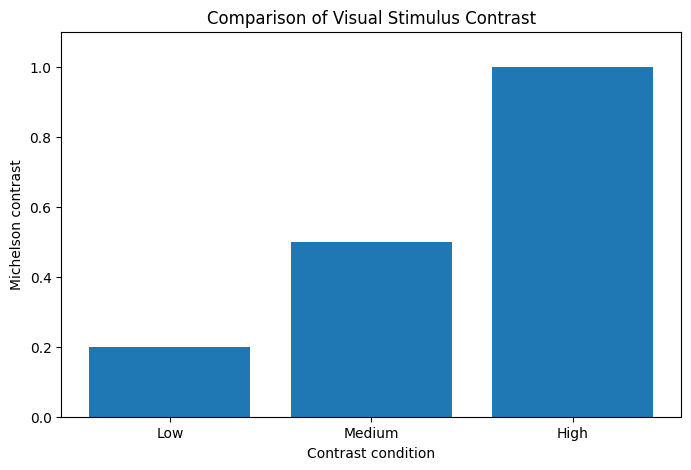

In [94]:

# Extract contrast values from our results table

contrast_values = results["Michelson contrast"]

# Create a bar graph

plt.figure(figsize=(8, 5))

plt.bar(
    ["Low", "Medium", "High"],
    contrast_values
)

plt.xlabel("Contrast condition")
plt.ylabel("Michelson contrast")

plt.title("Comparison of Visual Stimulus Contrast")

plt.ylim(0, 1.1)

plt.show()


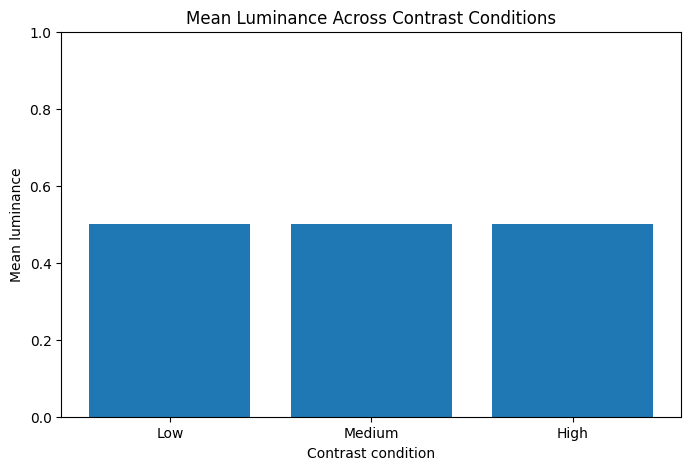

In [95]:

mean_values = results["Mean luminance"]

plt.figure(figsize=(8, 5))

plt.bar(
    ["Low", "Medium", "High"],
    mean_values
)

plt.xlabel("Contrast condition")
plt.ylabel("Mean luminance")

plt.title("Mean Luminance Across Contrast Conditions")

plt.ylim(0, 1)

plt.show()


STEP 2.13 — SPATIAL FREQUENCY MANIPULATION

In [96]:

# Define image dimensions

width = 500
height = 500

# Define three spatial frequencies

low_frequency = 2
medium_frequency = 5
high_frequency = 10

print("Low frequency:", low_frequency)
print("Medium frequency:", medium_frequency)
print("High frequency:", high_frequency)


Low frequency: 2
Medium frequency: 5
High frequency: 10


In [97]:

# Create horizontal coordinate values

x = np.linspace(0, 1, width, endpoint=False)

# Generate low-frequency grating

low_grating = np.sin(2 * np.pi * low_frequency * x)

# Generate medium-frequency grating

medium_grating = np.sin(2 * np.pi * medium_frequency * x)

# Generate high-frequency grating

high_grating = np.sin(2 * np.pi * high_frequency * x)

print("All three gratings have been generated!")


All three gratings have been generated!


In [98]:

# Convert sine waves into image intensity values

low_stimulus_sf = 0.5 + 0.5 * low_grating
medium_stimulus_sf = 0.5 + 0.5 * medium_grating
high_stimulus_sf = 0.5 + 0.5 * high_grating

# Repeat each row to create a 2D image

low_stimulus_sf = np.tile(low_stimulus_sf, (height, 1))
medium_stimulus_sf = np.tile(medium_stimulus_sf, (height, 1))
high_stimulus_sf = np.tile(high_stimulus_sf, (height, 1))

print("Three spatial-frequency images created!")


Three spatial-frequency images created!


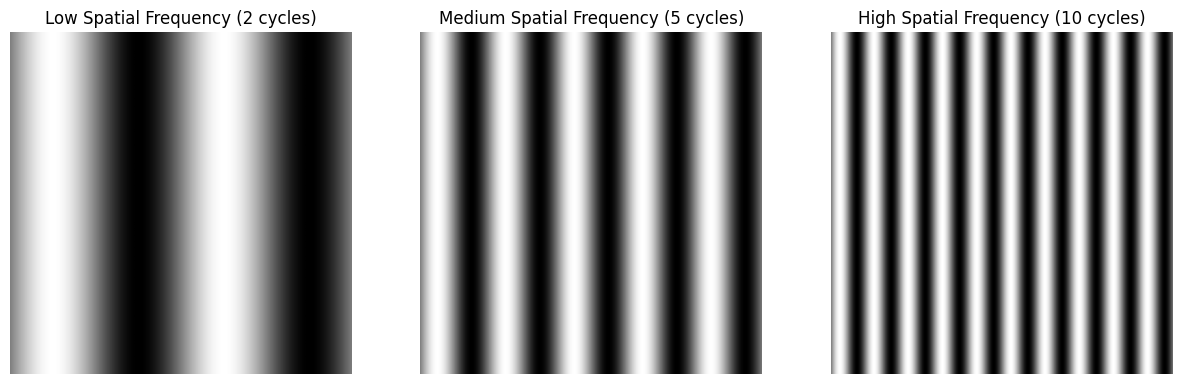

In [99]:

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(low_stimulus_sf, cmap="gray", vmin=0, vmax=1)
plt.title("Low Spatial Frequency (2 cycles)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(medium_stimulus_sf, cmap="gray", vmin=0, vmax=1)
plt.title("Medium Spatial Frequency (5 cycles)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(high_stimulus_sf, cmap="gray", vmin=0, vmax=1)
plt.title("High Spatial Frequency (10 cycles)")
plt.axis("off")

plt.show()


In [100]:
# Calculate spatial frequency in cycles per pixel

low_sf = low_frequency / width
medium_sf = medium_frequency / width
high_sf = high_frequency / width

print("Low spatial frequency:", low_sf, "cycles/pixel")
print("Medium spatial frequency:", medium_sf, "cycles/pixel")
print("High spatial frequency:", high_sf, "cycles/pixel")

Low spatial frequency: 0.004 cycles/pixel
Medium spatial frequency: 0.01 cycles/pixel
High spatial frequency: 0.02 cycles/pixel


In [101]:
# Measure luminance and contrast for each spatial-frequency stimulus

low_measurements = measure_stimulus(low_stimulus_sf)
medium_measurements = measure_stimulus(medium_stimulus_sf)
high_measurements = measure_stimulus(high_stimulus_sf)

print("LOW FREQUENCY")
print("Minimum:", low_measurements[0])
print("Maximum:", low_measurements[1])
print("Mean luminance:", low_measurements[2])
print("Michelson contrast:", low_measurements[3])

print("\nMEDIUM FREQUENCY")
print("Minimum:", medium_measurements[0])
print("Maximum:", medium_measurements[1])
print("Mean luminance:", medium_measurements[2])
print("Michelson contrast:", medium_measurements[3])

print("\nHIGH FREQUENCY")
print("Minimum:", high_measurements[0])
print("Maximum:", high_measurements[1])
print("Mean luminance:", high_measurements[2])
print("Michelson contrast:", high_measurements[3])

LOW FREQUENCY
Minimum: 3.947789809194413e-05
Maximum: 0.9999605221019081
Mean luminance: 0.5
Michelson contrast: 0.9999210442038162

MEDIUM FREQUENCY
Minimum: 0.0
Maximum: 1.0
Mean luminance: 0.5
Michelson contrast: 1.0

HIGH FREQUENCY
Minimum: 0.000986635785864165
Maximum: 0.9990133642141359
Mean luminance: 0.5
Michelson contrast: 0.9980267284282718


In [102]:
# Create a comparison table for spatial-frequency stimuli

spatial_frequency_results = pd.DataFrame({
    "Stimulus": ["Low", "Medium", "High"],
    "Spatial Frequency (cycles/pixel)": [
        low_sf, medium_sf, high_sf
    ],
    "Mean Luminance": [
        low_measurements[2],
        medium_measurements[2],
        high_measurements[2]
    ],
    "Michelson Contrast": [
        low_measurements[3],
        medium_measurements[3],
        high_measurements[3]
    ]
})

spatial_frequency_results

,Stimulus,Spatial Frequency (cycles/pixel),Mean Luminance,Michelson Contrast
0,Low,0.004,0.5,0.999921
1,Medium,0.010,0.5,1.000000
2,High,0.020,0.5,0.998027


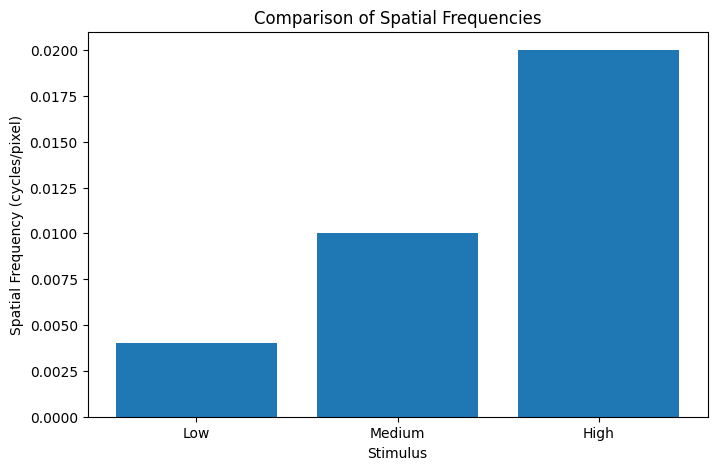

In [103]:
# Plot spatial-frequency comparison

plt.figure(figsize=(8, 5))

plt.bar(
    ["Low", "Medium", "High"],
    [low_sf, medium_sf, high_sf]
)

plt.xlabel("Stimulus")
plt.ylabel("Spatial Frequency (cycles/pixel)")
plt.title("Comparison of Spatial Frequencies")

plt.show()

Stage 2.14 — Orientation manipulation

In [104]:
# Define four stimulus orientations in degrees

orientations = [0, 45, 90, 135]

print("Orientations:", orientations)

Orientations: [0, 45, 90, 135]


In [105]:
# Create a 2D coordinate grid

x = np.linspace(-1, 1, width)
y = np.linspace(-1, 1, height)

X, Y = np.meshgrid(x, y)

print("2D coordinate grid created!")

2D coordinate grid created!


In [106]:
# Set spatial frequency for orientation experiment

orientation_frequency = 5

# Convert orientations from degrees to radians
orientation_radians = np.deg2rad(orientations)

print("Spatial frequency:", orientation_frequency)
print("Orientations in radians:", orientation_radians)

Spatial frequency: 5
Orientations in radians: [0.         0.78539816 1.57079633 2.35619449]


In [107]:
# Generate gratings at four different orientations

oriented_stimuli = []

for angle in orientation_radians:

    # Calculate rotated spatial coordinate
    rotated_coordinate = (
        X * np.cos(angle) + Y * np.sin(angle)
    )

    # Generate sinusoidal grating
    grating = np.sin(
        2 * np.pi * orientation_frequency * rotated_coordinate
    )

    # Convert intensity values from -1 to +1 into 0 to 1
    stimulus_image = 0.5 + 0.5 * grating

    # Store the stimulus
    oriented_stimuli.append(stimulus_image)

print("Four oriented gratings generated!")

Four oriented gratings generated!


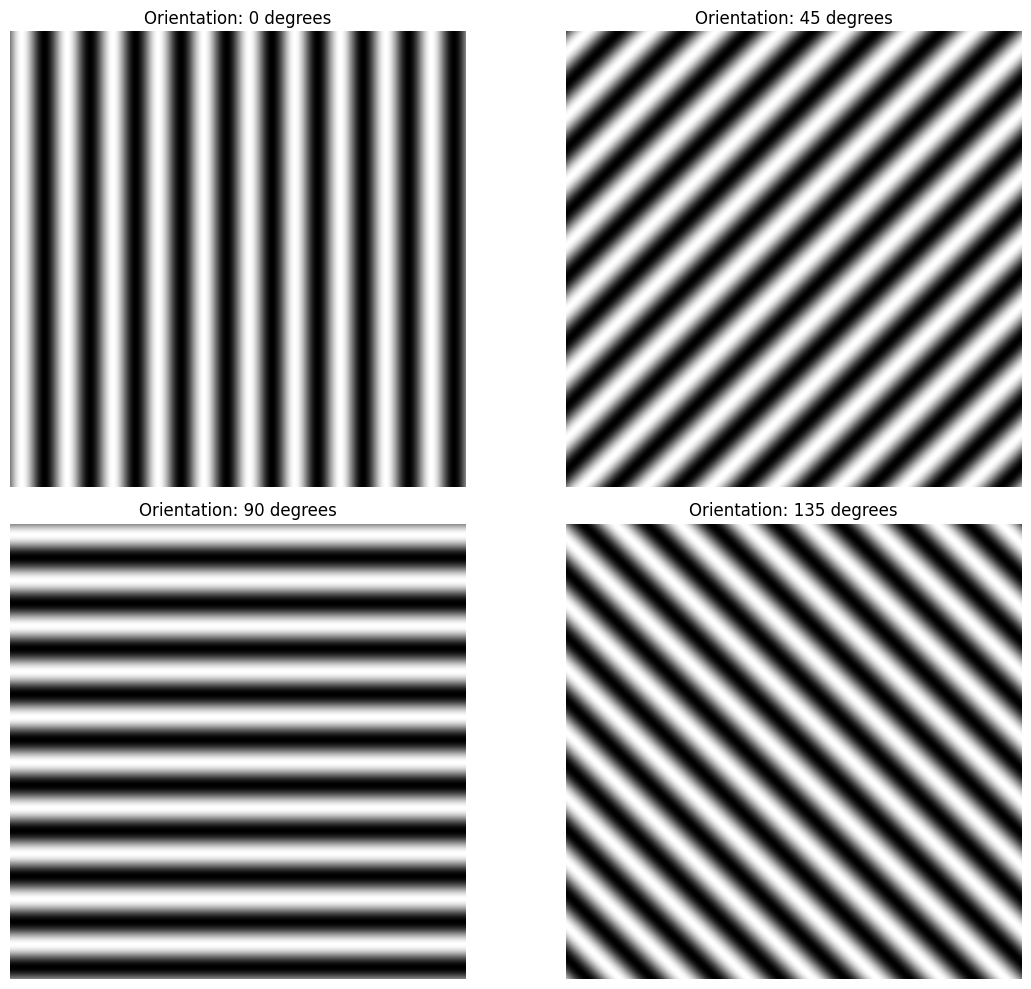

In [108]:
# Display all four oriented gratings

plt.figure(figsize=(12, 10))

for i in range(4):

    plt.subplot(2, 2, i + 1)

    plt.imshow(
        oriented_stimuli[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(f"Orientation: {orientations[i]} degrees")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [109]:
# Define actual stripe orientations

actual_orientations = [90, 135, 0, 45]

print("Actual stripe orientations:", actual_orientations)

Actual stripe orientations: [90, 135, 0, 45]


In [110]:
# Measure all four oriented stimuli

orientation_measurements = []

for stimulus_image in oriented_stimuli:

    measurements = measure_stimulus(stimulus_image)

    orientation_measurements.append(measurements)

print("Measurements completed!")

Measurements completed!


In [111]:
# Create orientation comparison table

orientation_results = pd.DataFrame({
    "Orientation (degrees)": actual_orientations,

    "Minimum Intensity": [
        m[0] for m in orientation_measurements
    ],

    "Maximum Intensity": [
        m[1] for m in orientation_measurements
    ],

    "Mean Luminance": [
        m[2] for m in orientation_measurements
    ],

    "Michelson Contrast": [
        m[3] for m in orientation_measurements
    ]
})

orientation_results

,Orientation (degrees),Minimum Intensity,Maximum Intensity,Mean Luminance,Michelson Contrast
0,90,0.000002,0.999998,0.5,0.999995
1,135,0.000007,0.999993,0.5,0.999987
2,0,0.000002,0.999998,0.5,0.999995
3,45,0.000007,0.999993,0.5,0.999987


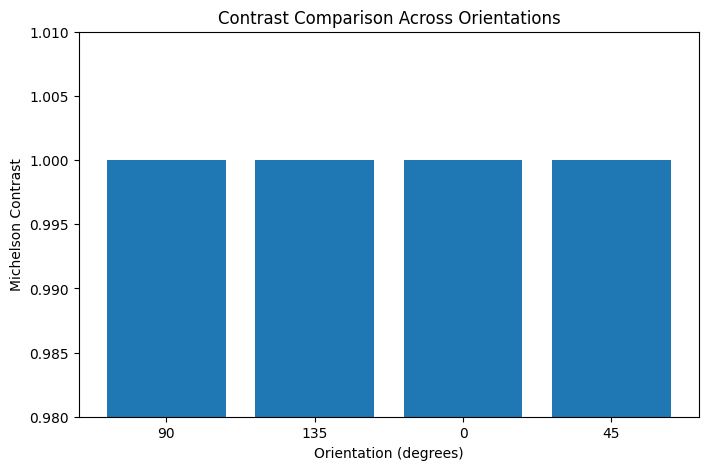

In [112]:
# Plot Michelson contrast across orientations

plt.figure(figsize=(8, 5))

plt.bar(
    orientation_results["Orientation (degrees)"].astype(str),
    orientation_results["Michelson Contrast"]
)

plt.xlabel("Orientation (degrees)")
plt.ylabel("Michelson Contrast")
plt.title("Contrast Comparison Across Orientations")

plt.ylim(0.98, 1.01)

plt.show()

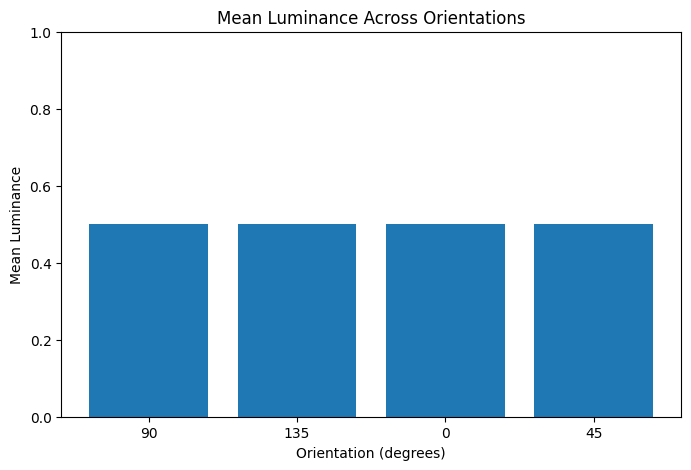

In [113]:
# Plot mean luminance across orientations

plt.figure(figsize=(8, 5))

plt.bar(
    orientation_results["Orientation (degrees)"].astype(str),
    orientation_results["Mean Luminance"]
)

plt.xlabel("Orientation (degrees)")
plt.ylabel("Mean Luminance")
plt.title("Mean Luminance Across Orientations")

plt.ylim(0, 1)

plt.show()

Stage 2.15 — Combining Spatial Frequency and Orientation

In [114]:
# Define spatial frequencies

frequencies = {
    "Low": 2,
    "High": 10
}

# Define orientations in degrees

test_orientations = [0, 90]

print("Frequencies:", frequencies)
print("Orientations:", test_orientations)

Frequencies: {'Low': 2, 'High': 10}
Orientations: [0, 90]


In [115]:
# Create an empty dictionary to store the stimuli

combined_stimuli = {}

# Generate all frequency-orientation combinations

for frequency_name, frequency_value in frequencies.items():

    for orientation in test_orientations:

        # Convert orientation to radians
        angle = np.deg2rad(orientation)

        # Calculate rotated spatial coordinate
        rotated_coordinate = (
            X * np.cos(angle) + Y * np.sin(angle)
        )

        # Generate sinusoidal grating
        grating = np.sin(
            2 * np.pi * frequency_value * rotated_coordinate
        )

        # Convert intensity values to 0-1
        stimulus_image = 0.5 + 0.5 * grating

        # Store the image using its condition name
        key = f"{frequency_name}_{orientation}"

        combined_stimuli[key] = stimulus_image

print("Four combined stimuli generated!")

Four combined stimuli generated!


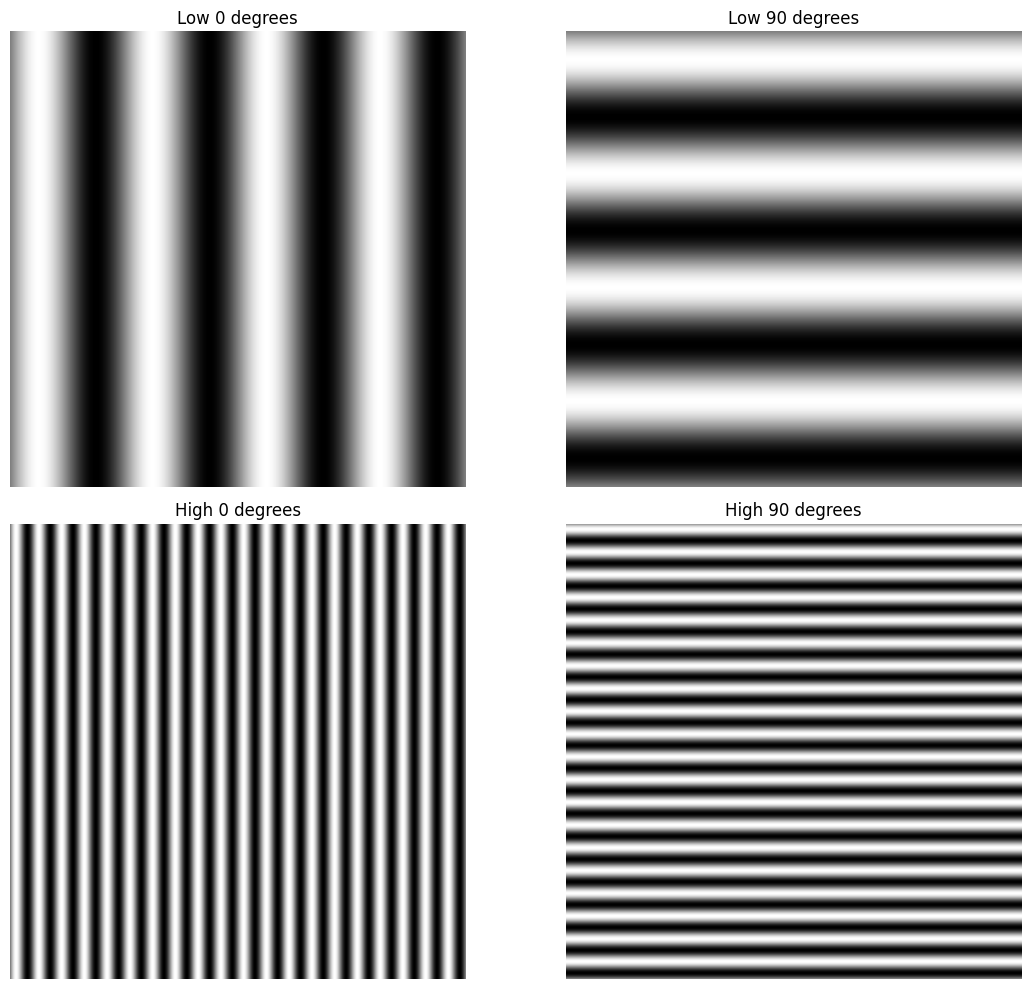

In [116]:
# Display all four combined stimuli

plt.figure(figsize=(12, 10))

stimulus_names = ["Low_0", "Low_90", "High_0", "High_90"]

for i, name in enumerate(stimulus_names):

    plt.subplot(2, 2, i + 1)

    plt.imshow(
        combined_stimuli[name],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(name.replace("_", " ") + " degrees")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [117]:
# Measure all four combined stimuli

combined_measurements = []

for name in stimulus_names:

    image = combined_stimuli[name]

    measurements = measure_stimulus(image)

    combined_measurements.append([
        name,
        measurements[0],
        measurements[1],
        measurements[2],
        measurements[3]
    ])

print("Measurements for all four stimuli completed!")

Measurements for all four stimuli completed!


In [119]:
# Create a comparison table

combined_results = pd.DataFrame(
    combined_measurements,
    columns=[
        "Stimulus",
        "Minimum Intensity",
        "Maximum Intensity",
        "Mean Luminance",
        "Michelson Contrast"
    ]
)

# Add spatial frequency in cycles per pixel

combined_results["Spatial Frequency (cycles/pixel)"] = [
    2/width, 2/width, 10/width, 10/width
]

# Add actual stripe orientation

combined_results["Stripe Orientation (degrees)"] = [
    90, 0, 90, 0
]

combined_results

,Stimulus,Minimum Intensity,Maximum Intensity,Mean Luminance,Michelson Contrast,Spatial Frequency (cycles/pixel),Stripe Orientation (degrees)
0,Low_0,0.000002,0.999998,0.5,0.999995,0.004,90
1,Low_90,0.000002,0.999998,0.5,0.999995,0.004,0
2,High_0,0.000002,0.999998,0.5,0.999995,0.020,90
3,High_90,0.000002,0.999998,0.5,0.999995,0.020,0


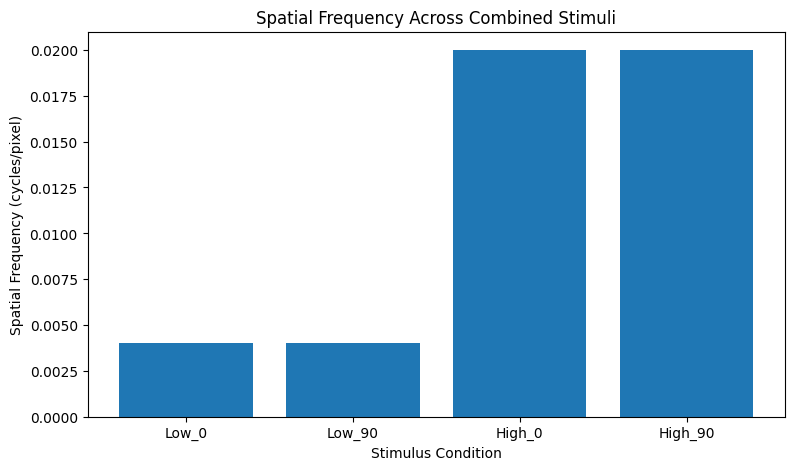

In [120]:
# Compare spatial frequency across stimulus conditions

plt.figure(figsize=(9, 5))

plt.bar(
    combined_results["Stimulus"],
    combined_results["Spatial Frequency (cycles/pixel)"]
)

plt.xlabel("Stimulus Condition")
plt.ylabel("Spatial Frequency (cycles/pixel)")
plt.title("Spatial Frequency Across Combined Stimuli")

plt.show()

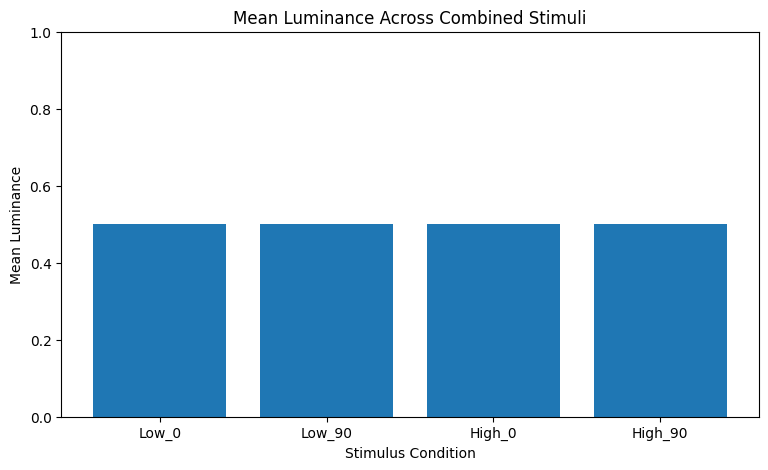

In [121]:
# Compare mean luminance across stimulus conditions

plt.figure(figsize=(9, 5))

plt.bar(
    combined_results["Stimulus"],
    combined_results["Mean Luminance"]
)

plt.xlabel("Stimulus Condition")
plt.ylabel("Mean Luminance")
plt.title("Mean Luminance Across Combined Stimuli")

plt.ylim(0, 1)

plt.show()

Stage 2.16 — Introduction to Gabor patches